# Remote Work Of Health Impact

Section 34T | DS111

Aryam Alanazi    | 447002330

Renad Alruwaili  | 447005303

# The description
The dataset contains comprehensive information about employees to study the impact of work models (Remote, Hybrid, On-Site) on health and lifestyle, including working hours, sleep duration, physical activity, stress levels, and burnout risk indicators. The analysis aims to identify patterns and risk factors contributing to workplace stress and burnout, aiding in early detection, employee wellness promotion, and management strategies.

# The goals
1-Explore the main factors associated with the risk of employee burnout and stress in different work environments.

2-Create appropriate graphical visualizations to illustrate trends, and relationships in the dataset.

3-Handle lost/missing data to ensure the accuracy and reliability of the analysis.

4-Build machine learning models to predict employee burnout risk

https://work-predictor-k23ks3vrcfm8elyascatcq.streamlit.app/

# 1. Importing the libraries

In [1]:
# Import the basic libraries for data handling and plotting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

# Apply the default seaborn theme
sns.set_theme()

# Import train & test split to split the data into training and test sets
from sklearn.model_selection import train_test_split # Splits datasets into random train and test subsets.

# Import pipeline & scaler (used with the models that need scaled features)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# Import classifiers/models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

# Import model evaluation metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score

# 2. Loading the dataset (a)

In [2]:
# Loading the data
file_name = glob.glob('*.csv')[0]
df = pd.read_csv(file_name)

# Check and print the number of rows and columns in the dataset
print(df.shape)

(3157, 14)


### Print the first and the last rows

In [3]:
# Print the first five rows
df.head()

,Survey_Date,Age,Gender,Region,Industry,Job_Role,Work_Arrangement,Hours_Per_Week,Mental_Health_Status,Burnout_Level,Work_Life_Balance_Score,Physical_Health_Issues,Social_Isolation_Score,Salary_Range
0,2025-06-01,27,Female,Asia,Professional Services,Data Analyst,Onsite,64,Stress Disorder,High,3,Shoulder Pain; Neck Pain,2,$40K-60K
1,2025-06-01,37,Female,Asia,Professional Services,Data Analyst,Onsite,37,Stress Disorder,High,4,Back Pain,2,$80K-100K
2,2025-06-01,32,Female,Africa,Education,Business Analyst,Onsite,36,ADHD,High,3,Shoulder Pain; Eye Strain,2,$80K-100K
3,2025-06-01,40,Female,Europe,Education,Data Analyst,Onsite,63,ADHD,Medium,1,Shoulder Pain; Eye Strain,2,$60K-80K
4,2025-06-01,30,Male,South America,Manufacturing,DevOps Engineer,Hybrid,65,NaN,Medium,5,NaN,4,$60K-80K


In [4]:
# Print the last five rows
df.tail()

,Survey_Date,Age,Gender,Region,Industry,Job_Role,Work_Arrangement,Hours_Per_Week,Mental_Health_Status,Burnout_Level,Work_Life_Balance_Score,Physical_Health_Issues,Social_Isolation_Score,Salary_Range
3152,2025-06-26,62,Female,South America,Professional Services,Data Analyst,Hybrid,38,PTSD,Medium,4,Shoulder Pain; Neck Pain,3,$80K-100K
3153,2025-06-26,24,Female,South America,Professional Services,Software Engineer,Remote,54,NaN,Medium,4,Eye Strain,4,$100K-120K
3154,2025-06-26,45,Female,North America,Professional Services,HR Manager,Onsite,59,PTSD,Medium,1,Shoulder Pain,3,$40K-60K
3155,2025-06-26,38,Male,North America,Education,Operations Manager,Onsite,52,Depression,Medium,3,Shoulder Pain; Eye Strain; Neck Pain,5,$80K-100K
3156,2025-06-26,54,Female,North America,Healthcare,Technical Writer,Onsite,39,Burnout,Medium,4,Back Pain; Eye Strain,2,$100K-120K


### Dataset information
- **Source file:** `post_pandemic_remote_work_health_impact_2025.csv` (survey responses collected from 2025-06-01 to 2025-06-26).
- **Size:** 3157 rows and 14 columns before cleaning.

| Column | Description |
|---|---|
| Survey_Date | The date of the survey response |
| Age | Age of the employee (22 to 65) |
| Gender | Male, Female, Non-binary, Prefer not to say |
| Region | The region of the employee (6 regions) |
| Industry | The industry the employee works in (9 industries) |
| Job_Role | The job role of the employee (24 roles) |
| Work_Arrangement | Onsite, Hybrid or Remote (**the target we predict**) |
| Hours_Per_Week | Working hours per week (35 to 65) |
| Mental_Health_Status | Reported mental health condition (6 categories) |
| Burnout_Level | Low, Medium or High |
| Work_Life_Balance_Score | Score from 1 to 5 |
| Physical_Health_Issues | Reported physical issues, separated by ";" (31 combinations) |
| Social_Isolation_Score | Score from 1 to 5 |
| Salary_Range | Salary range of the employee (5 ranges) |

### Basic summary statistics

In [5]:
# Print statistic summary for the numerical columns
df.describe().round(2)

,Age,Hours_Per_Week,Work_Life_Balance_Score,Social_Isolation_Score
count,3157.00,3157.0,3157.00,3157.00
mean,43.73,49.9,3.00,2.70
std,12.66,8.9,1.16,1.19
min,22.00,35.0,1.00,1.00
25%,33.00,42.0,2.00,2.00
50%,44.00,50.0,3.00,3.00
75%,55.00,57.0,4.00,4.00
max,65.00,65.0,5.00,5.00


# 3. Data Preprocessing (b)

## 3.1 Missing data

In [6]:
# Check and display the number of missing values in each column
print(df.isnull().sum())

Survey_Date                  0
Age                          0
Gender                       0
Region                       0
Industry                     0
Job_Role                     0
Work_Arrangement             0
Hours_Per_Week               0
Mental_Health_Status       799
Burnout_Level                0
Work_Life_Balance_Score      0
Physical_Health_Issues     280
Social_Isolation_Score       0
Salary_Range                 0
dtype: int64


Only two columns have missing values: **Mental_Health_Status** (799 missing) and **Physical_Health_Issues** (280 missing). All the other columns are complete.

In [7]:
# Option 1: Remove the rows that have null values (dropna)
print('Shape before:', df.shape)
df_dropna = df.dropna()
print('Shape after removing the rows with null values:', df_dropna.shape)

# Option 2 (shown for comparison): Replace the empty values using the mode of each column
df_mode = df.copy()
for col in ['Mental_Health_Status', 'Physical_Health_Issues']:
    df_mode[col] = df_mode[col].fillna(df_mode[col].mode()[0])
print('Shape after replacing the empty values with the mode:', df_mode.shape)
print('Missing values left after the mode replacement:', df_mode.isnull().sum().sum())

Shape before: (3157, 14)
Shape after removing the rows with null values: (2150, 14)
Shape after replacing the empty values with the mode: (3157, 14)
Missing values left after the mode replacement: 0


**Chosen method: Option 1 (remove the rows with missing values).** Both columns are text columns (health conditions), so the mean and the median cannot be used, and filling them with the mode would invent a health condition for the employees who did not report one. Removing the rows leaves **2150 complete rows** (1007 rows removed), which is still enough to train the models.

In [8]:
# Apply the chosen method on our dataset
df = df.dropna()
print(df.shape)

(2150, 14)


## 3.2 Redundancies (duplicate rows)

In [9]:
# Check the number of duplicate rows
print('Duplicate rows:', df.duplicated().sum())

# Remove the duplicate rows
df = df.drop_duplicates()
print(df.shape)

Duplicate rows: 0
(2150, 14)


There are no duplicate rows in the dataset, so no rows were removed.

## 3.3 Outliers

In [10]:
# Count the outliers in each numerical column using the Interquartile Range (IQR) method
for col in df.select_dtypes(include=['number']).columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    print(col, '-> outliers:', n_outliers)

Age -> outliers: 0
Hours_Per_Week -> outliers: 0
Work_Life_Balance_Score -> outliers: 0
Social_Isolation_Score -> outliers: 0


In [11]:
# Handle outliers in numerical columns using the Interquartile Range (IQR) method
# (any value outside the bounds is replaced by the nearest bound)
for col in df.select_dtypes(include=['number']).columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    df[col] = np.where(df[col] < lower_bound, lower_bound, df[col])
    df[col] = np.where(df[col] > upper_bound, upper_bound, df[col])

print(df.shape)

(2150, 14)


The IQR method found **no outliers** in any numerical column, so the values were not changed. The cleaned dataset has **2150 rows and 14 columns**.

# 4. Exploratory Data Analysis - EDA (c)

## 1D (univariate analysis)

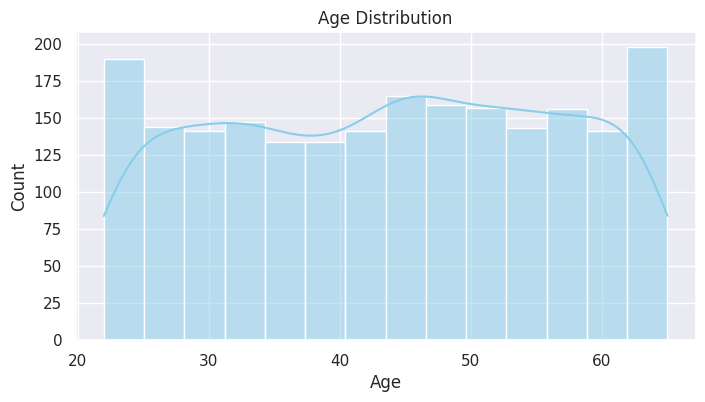

In [12]:
# Plot the age distribution using a histogram and KDE curve
plt.figure(figsize=(8, 4))
sns.histplot(df['Age'], kde=True, color='skyblue')
plt.title('Age Distribution')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

Result: The ages range from 22 to 65 (mean 43.8, median 44) and they are spread fairly evenly across all the working ages, so the participants represent different career stages.

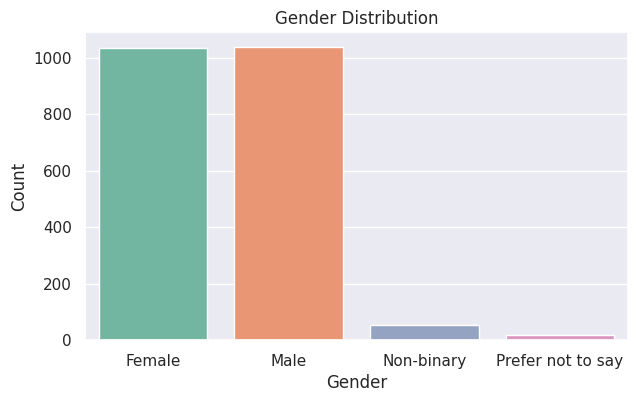

In [13]:
# Plot the gender distribution using a count plot
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Gender', hue='Gender', palette='Set2', legend=False)
plt.title('Gender Distribution')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.show()

Result: Males (1039) and females (1036) are almost equal in number, which gives a fair comparison between them. Non-binary (55) and Prefer not to say (20) are very small groups.

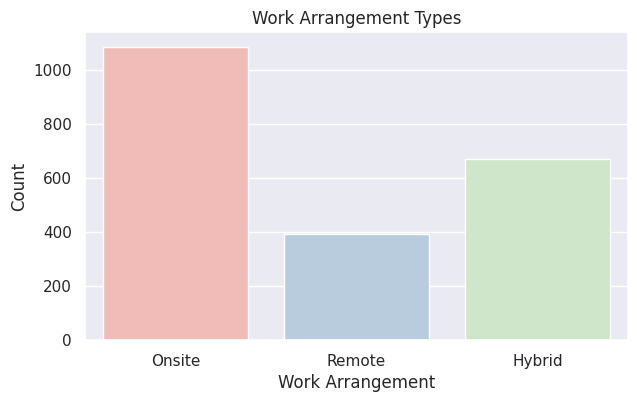

In [14]:
# Plot the distribution of work arrangement types (our target) using a count plot
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Work_Arrangement', hue='Work_Arrangement', palette='Pastel1', legend=False)
plt.title('Work Arrangement Types')
plt.xlabel('Work Arrangement')
plt.ylabel('Count')
plt.show()

Result: Onsite is the largest group (1086 employees, 50.5%), then Hybrid (672, 31.3%) and Remote (392, 18.2%). The classes are not balanced.

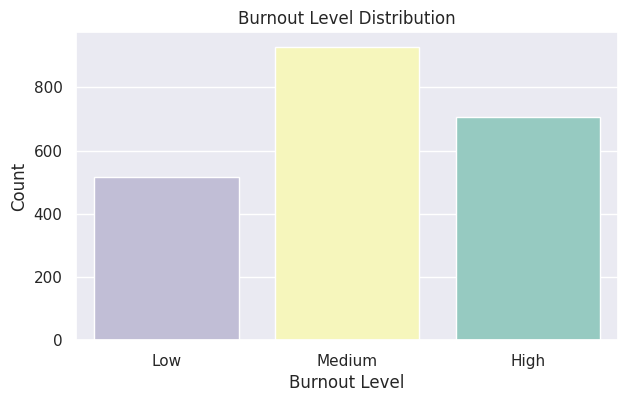

In [15]:
# Plot the burnout level distribution using a count plot
plt.figure(figsize=(7, 4))
sns.countplot(data=df, x='Burnout_Level', hue='Burnout_Level', order=['Low', 'Medium', 'High'], palette='Set3', legend=False)
plt.title('Burnout Level Distribution')
plt.xlabel('Burnout Level')
plt.ylabel('Count')
plt.show()

Result: Medium burnout is the most common (928, 43.2%), followed by High (705, 32.8%) and Low (517, 24.0%).

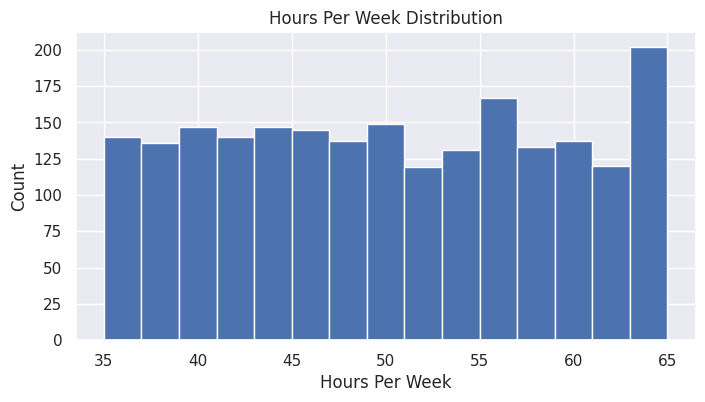

In [16]:
# Plot the weekly working hours using a histogram
plt.figure(figsize=(8, 4))
plt.hist(df['Hours_Per_Week'], bins=15)
plt.xlabel('Hours Per Week')
plt.ylabel('Count')
plt.title('Hours Per Week Distribution')
plt.show()

Result: Working hours range from 35 to 65 hours per week, with an average of about 50 hours.

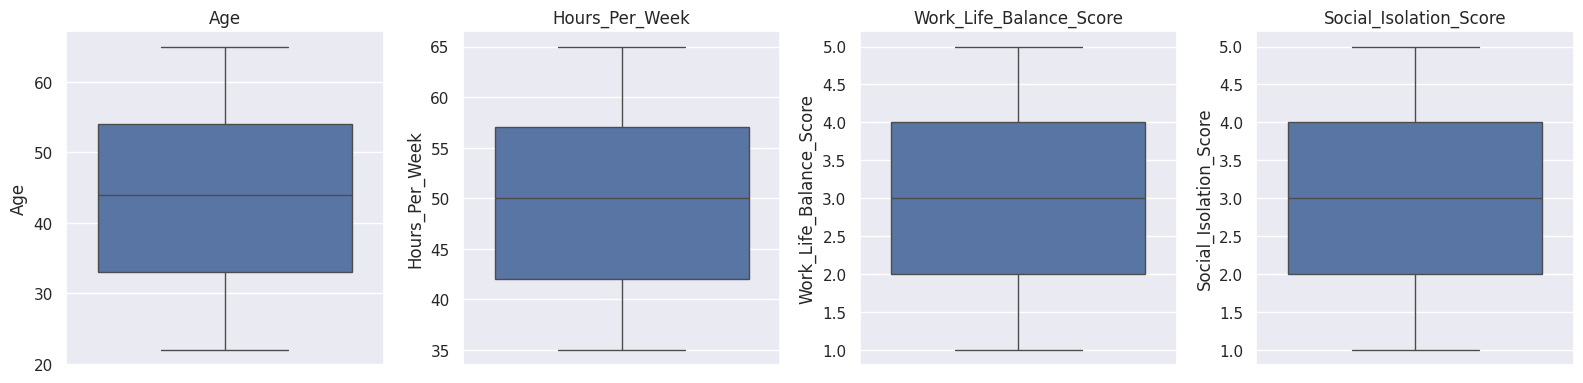

In [17]:
# Plot a box plot for each numerical variable to see the median, the quartiles and the outliers
numeric_cols = ['Age', 'Hours_Per_Week', 'Work_Life_Balance_Score', 'Social_Isolation_Score']
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Result: The box plots show the median and the quartiles of each numerical variable. No points appear outside the whiskers, which confirms that there are no outliers.

## 2D (bivariate analysis)

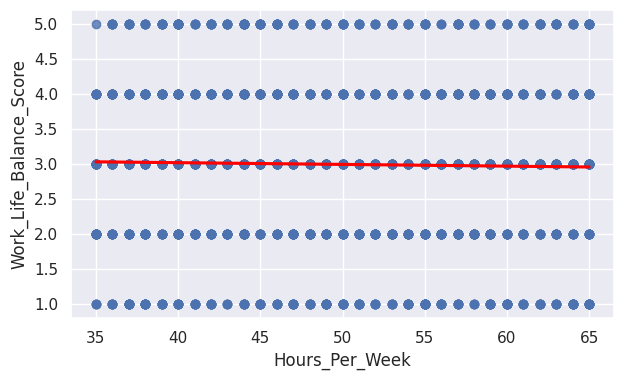

Correlation coefficient =  -0.02


In [18]:
# Scatter plot with a regression line between weekly hours and work-life balance, with the correlation coefficient
plt.figure(figsize=(7, 4))
sns.regplot(x=df['Hours_Per_Week'], y=df['Work_Life_Balance_Score'], ci=None, line_kws={"color": "red"})
plt.show()
print('Correlation coefficient = ', np.corrcoef(df['Hours_Per_Week'], df['Work_Life_Balance_Score'])[0, 1].round(2))

Result: The correlation coefficient is -0.02, so there is almost no linear relation between the working hours and the work-life balance score.

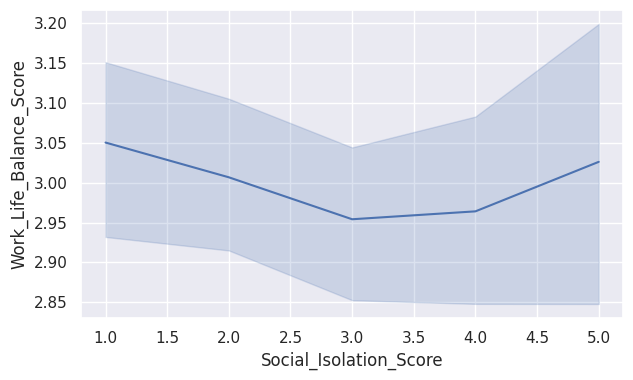

In [19]:
# Line plot to track the work-life balance score for each social isolation score
plt.figure(figsize=(7, 4))
sns.lineplot(data=df, x='Social_Isolation_Score', y='Work_Life_Balance_Score')
plt.show()

Result: The line stays around 3 for all the social isolation scores, so the work-life balance score does not change with the social isolation score.

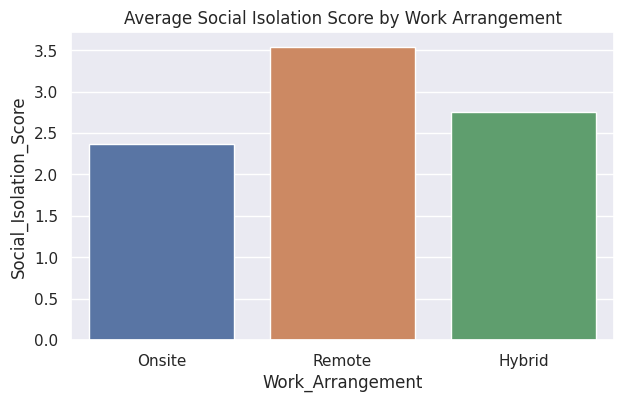

In [20]:
# Bar plot of the average social isolation score for each work arrangement
plt.figure(figsize=(7, 4))
sns.barplot(data=df, x='Work_Arrangement', y='Social_Isolation_Score', hue='Work_Arrangement', errorbar=None, legend=False)
plt.title('Average Social Isolation Score by Work Arrangement')
plt.show()

Result: Remote employees have the highest average social isolation score (3.54), then Hybrid (2.75), and Onsite employees have the lowest (2.37).

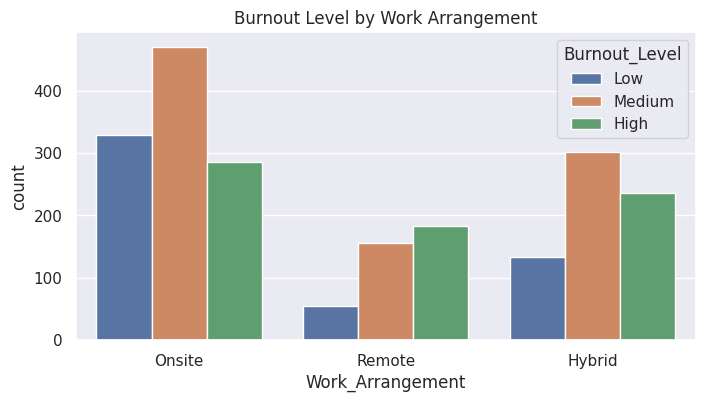

In [21]:
# Count plot comparing the burnout levels inside each work arrangement
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x='Work_Arrangement', hue='Burnout_Level', hue_order=['Low', 'Medium', 'High'])
plt.title('Burnout Level by Work Arrangement')
plt.show()

Result: High burnout is the most frequent level among Remote employees (46.7% of them, compared with 35.1% for Hybrid and 26.3% for Onsite), while Low burnout is the most frequent among Onsite employees (30.3% compared with 13.8% for Remote).

## 3D (multivariate analysis)

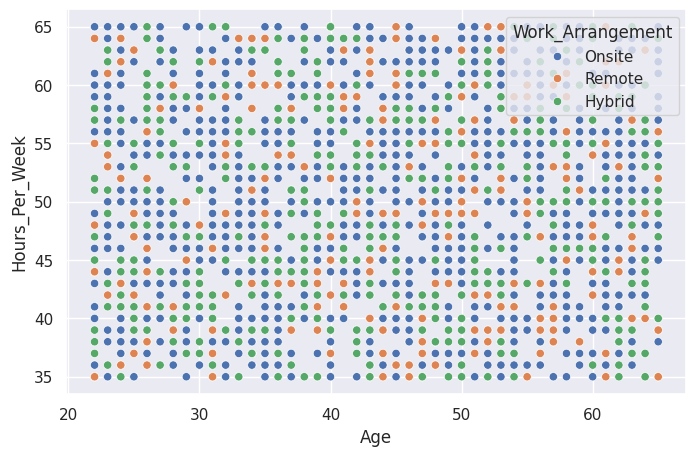

In [22]:
# Scatter plot of age and weekly hours colored by work arrangement (3 variables)
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x='Age', y='Hours_Per_Week', hue='Work_Arrangement')
plt.show()

Result: The points of the three work arrangements are mixed together over all the ages and working hours, so age and hours alone do not separate the work arrangements.

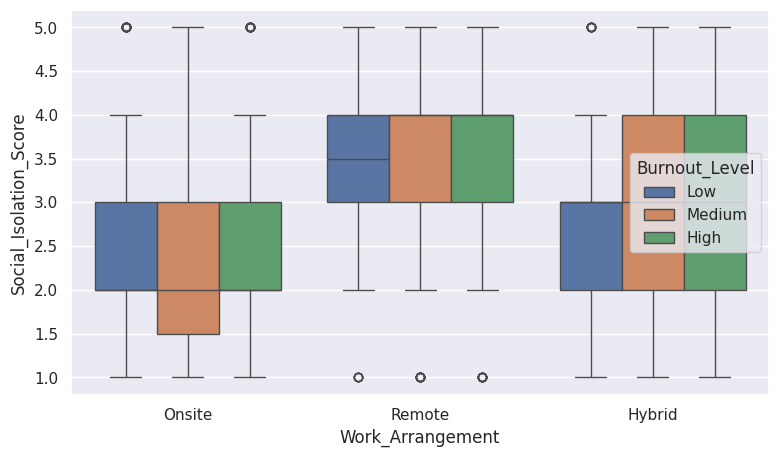

In [23]:
# Box plot of the social isolation score for each work arrangement, split by burnout level (3 variables)
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x='Work_Arrangement', y='Social_Isolation_Score', hue='Burnout_Level', hue_order=['Low', 'Medium', 'High'])
plt.show()

Result: Remote employees have higher social isolation scores than Hybrid and Onsite employees at every burnout level, so the isolation score is related to the work arrangement more than to the burnout level.

## More than 3D

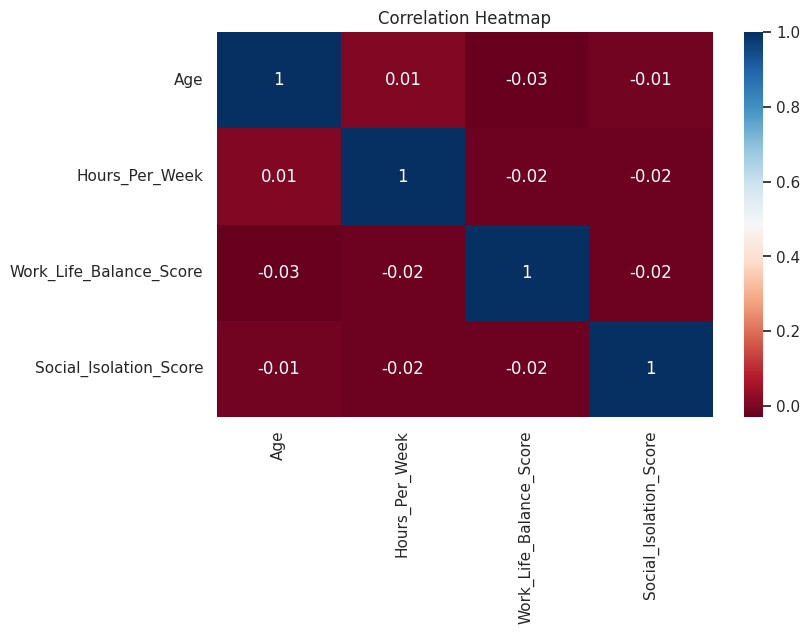

In [24]:
# Heat map of the correlation between the numerical variables
plt.figure(figsize=(8, 5))
corrHeatMap = df.corr(numeric_only=True).round(2)
sns.heatmap(corrHeatMap, cmap='RdBu', annot=True)
plt.title('Correlation Heatmap')
plt.show()

Result: All the correlations between the numerical variables are close to zero (between -0.03 and 0.01), so there are no strong linear relations between them.

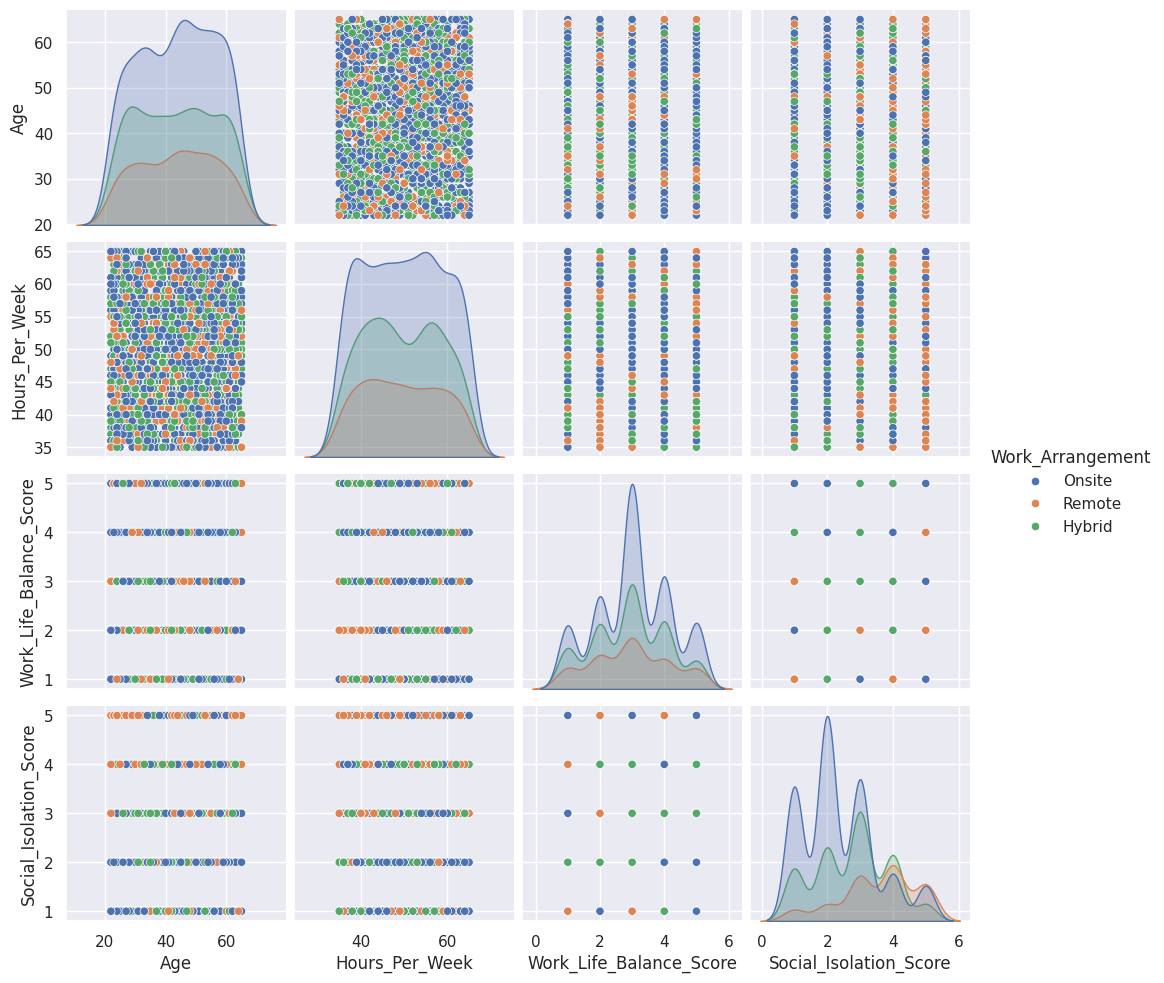

In [25]:
# Pair plot of the numerical variables colored by work arrangement
sns.pairplot(df[numeric_cols + ['Work_Arrangement']], hue='Work_Arrangement')
plt.show()

Result: The pair plot shows the distribution of every numerical variable and the relation between each pair of them. The three work arrangements overlap in all the plots, which suggests that predicting the work arrangement will be a hard task.

# 5. Machine Learning Models (d) and Evaluation (e)

Following Lab 5, we use four different algorithms: **Logistic Regression, Decision Tree, Random Forest and K-Nearest Neighbors** to predict the target **Work_Arrangement**. After each model we evaluate it directly with the same evaluation code: confusion matrix, classification report and four performance metrics (**Accuracy, Precision, Recall and F1-score**) in addition to the ROC AUC.

## 5.1 Prepare the data

In [26]:
# Convert the categorical (text) columns to numbers so the models can use them.
# np.where works for a column with 2 values only (e.g. Male/Female), but our columns have 3 to 31 values,
# so we use pd.factorize (as in Lab 6), which gives every value its own number.
df_ml = df.copy()
for col in df_ml.columns:
    if not pd.api.types.is_numeric_dtype(df_ml[col]):
        df_ml[col] = pd.factorize(df_ml[col], sort=True)[0]

# The numbers given to the target classes
print(dict(enumerate(sorted(df['Work_Arrangement'].unique()))))
df_ml.head()

{0: 'Hybrid', 1: 'Onsite', 2: 'Remote'}


,Survey_Date,Age,Gender,Region,Industry,Job_Role,Work_Arrangement,Hours_Per_Week,Mental_Health_Status,Burnout_Level,Work_Life_Balance_Score,Physical_Health_Issues,Social_Isolation_Score,Salary_Range
0,0,27.0,0,1,6,5,1,64.0,5,0,3.0,27,2.0,2
1,0,37.0,0,1,6,5,1,37.0,5,0,4.0,0,2.0,4
2,0,32.0,0,0,1,1,1,36.0,0,0,3.0,23,2.0,4
3,0,40.0,0,2,1,5,1,63.0,0,2,1.0,23,2.0,3
5,0,52.0,1,4,0,1,1,61.0,2,2,4.0,7,3.0,3


The target classes are numbered: **0 = Hybrid, 1 = Onsite, 2 = Remote** (this is how the classes appear in the confusion matrices).

In [27]:
# Set the features (X) and the target (y)
target_column = 'Work_Arrangement'
X = df_ml.drop(columns=[target_column])
y = df_ml[target_column]

# Split the data into 70% training and 30% testing sets (as in Lab 5)
# random_state=101 ensures the split is reproducible.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=101)
print(X_train.shape, X_test.shape)

(1505, 13) (645, 13)


In [28]:
# A dictionary to keep the evaluation metrics of every model
results = {}

# A function that calculates the four performance metrics + ROC AUC (weighted average because the target has 3 classes)
def evaluate(name, model, pred):
    results[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_test, pred, average='weighted', zero_division=0),
        'F1-score': f1_score(y_test, pred, average='weighted', zero_division=0),
        'ROC AUC': roc_auc_score(y_test, model.predict_proba(X_test), multi_class='ovr')
    }
    for metric, value in results[name].items():
        print(f"{metric}: {value:.4f}")

## 5.2 Logistic Regression

In [29]:
# Creating Logistic Regression model (with scaling, as the model needs scaled features)
logmodel = make_pipeline(StandardScaler(), LogisticRegression())

# Fitting the training data
logmodel.fit(X_train, y_train)

# Predicting on the test set
pred = logmodel.predict(X_test)

In [30]:
# Printing confusion matrix, classification report and accuracy
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print(accuracy_score(y_test, pred))

[[ 30 148  32]
 [ 25 272  31]
 [ 13  55  39]]
              precision    recall  f1-score   support

           0       0.44      0.14      0.22       210
           1       0.57      0.83      0.68       328
           2       0.38      0.36      0.37       107

    accuracy                           0.53       645
   macro avg       0.47      0.45      0.42       645
weighted avg       0.50      0.53      0.48       645

0.5286821705426357


Confusion matrix


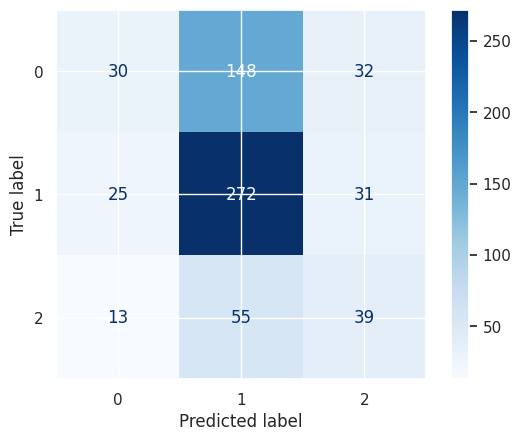

Normalized confusion matrix


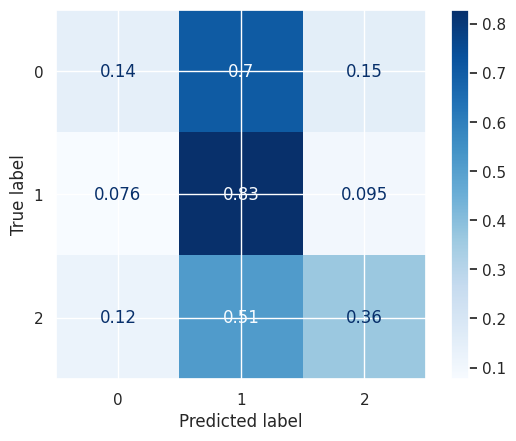

In [31]:
# Confusion matrix without normalization
print('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap='Blues')
plt.show()

# Normalized confusion matrix
print('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap='Blues')
plt.show()

In [32]:
# Calculate the four performance metrics and the ROC AUC of the model
evaluate('Logistic Regression', logmodel, pred)

Accuracy: 0.5287
Precision: 0.4983
Recall: 0.5287
F1-score: 0.4767
ROC AUC: 0.6528


Result: Logistic Regression has an accuracy of **0.5287** (ROC AUC 0.6528). The matrix shows that it predicts the Onsite class most of the time (272 of the 328 Onsite employees are correct), but it recognizes only 30 of the 210 Hybrid employees.

## 5.3 Decision Tree

In [33]:
# Creating Decision Tree model
DT = DecisionTreeClassifier(random_state=42)

# Fitting the training data
DT.fit(X_train, y_train)

# Predicting on the test set
pred = DT.predict(X_test)

In [34]:
# Printing confusion matrix, classification report and accuracy
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print(accuracy_score(y_test, pred))

[[ 78  94  38]
 [ 98 181  49]
 [ 49  27  31]]
              precision    recall  f1-score   support

           0       0.35      0.37      0.36       210
           1       0.60      0.55      0.57       328
           2       0.26      0.29      0.28       107

    accuracy                           0.45       645
   macro avg       0.40      0.40      0.40       645
weighted avg       0.46      0.45      0.45       645

0.4496124031007752


Confusion matrix


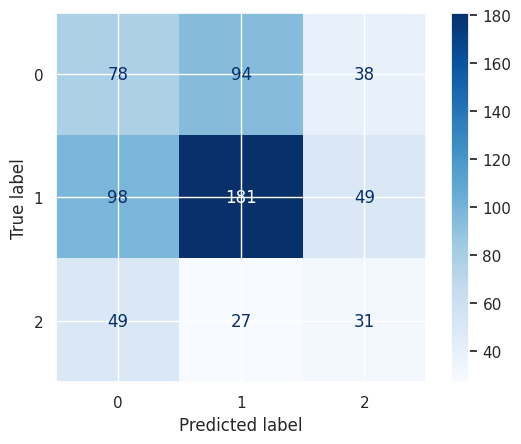

Normalized confusion matrix


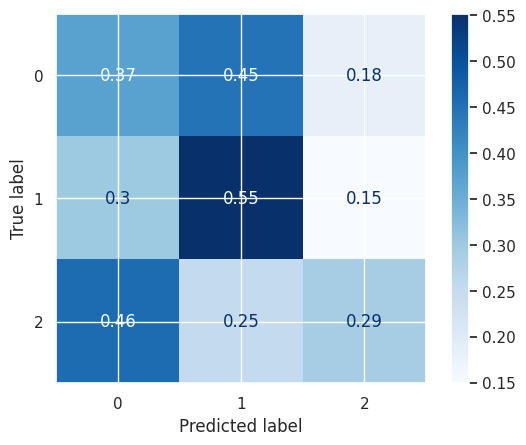

In [35]:
# Confusion matrix without normalization
print('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap='Blues')
plt.show()

# Normalized confusion matrix
print('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap='Blues')
plt.show()

In [36]:
# Calculate the four performance metrics and the ROC AUC of the model
evaluate('Decision Tree', DT, pred)

Accuracy: 0.4496
Precision: 0.4612
Recall: 0.4496
F1-score: 0.4547
ROC AUC: 0.5553


Result: The Decision Tree has an accuracy of **0.4496** (ROC AUC 0.5553), the lowest accuracy of the four models. It spreads its predictions between the three classes (181 of the 328 Onsite employees are correct), which suggests that the tree is overfitting the training data.

## 5.4 Random Forest

In [37]:
# Creating Random Forest model
RF = RandomForestClassifier(n_estimators=100, random_state=0)

# Fitting the training data
RF.fit(X_train, y_train)

# Predicting on the test set
pred = RF.predict(X_test)

In [38]:
# Printing confusion matrix, classification report and accuracy
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print(accuracy_score(y_test, pred))

[[ 63 118  29]
 [ 46 267  15]
 [ 42  38  27]]
              precision    recall  f1-score   support

           0       0.42      0.30      0.35       210
           1       0.63      0.81      0.71       328
           2       0.38      0.25      0.30       107

    accuracy                           0.55       645
   macro avg       0.48      0.46      0.45       645
weighted avg       0.52      0.55      0.53       645

0.5534883720930233


Confusion matrix


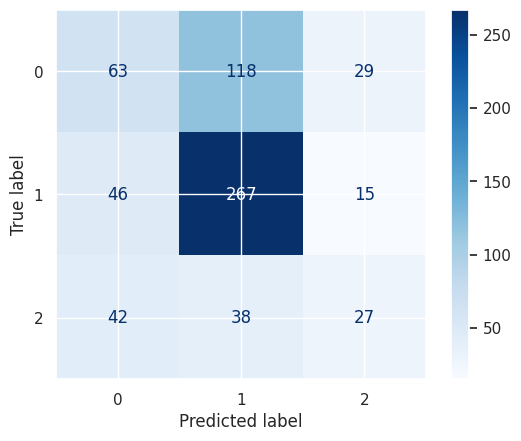

Normalized confusion matrix


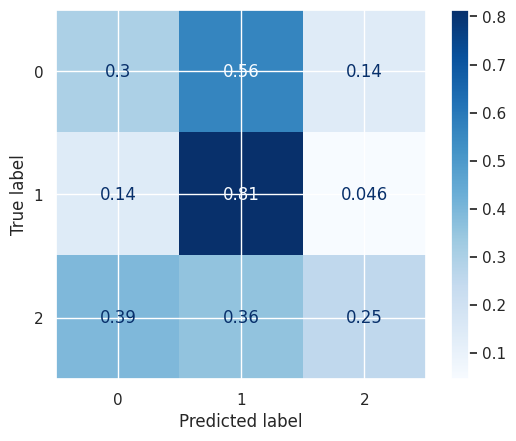

In [39]:
# Confusion matrix without normalization
print('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap='Blues')
plt.show()

# Normalized confusion matrix
print('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap='Blues')
plt.show()

In [40]:
# Calculate the four performance metrics and the ROC AUC of the model
evaluate('Random Forest', RF, pred)

Accuracy: 0.5535
Precision: 0.5199
Recall: 0.5535
F1-score: 0.5256
ROC AUC: 0.6701


Result: Random Forest has the highest accuracy **0.5535** and the highest ROC AUC (0.6701). It recognizes 267 of the 328 Onsite employees and 63 of the 210 Hybrid employees, but only 27 of the 107 Remote employees.

## 5.5 K-Nearest Neighbors

In [50]:
# Creating KNN model
knn = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=4))  # try k = 2, 3, 4

# Fitting the training data
knn.fit(X_train, y_train)

# Predicting on the test set
pred = knn.predict(X_test)

In [52]:
# Printing confusion matrix, classification report and accuracy
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))
print(accuracy_score(y_test, pred))

[[ 85 105  20]
 [111 190  27]
 [ 47  43  17]]
              precision    recall  f1-score   support

           0       0.35      0.40      0.38       210
           1       0.56      0.58      0.57       328
           2       0.27      0.16      0.20       107

    accuracy                           0.45       645
   macro avg       0.39      0.38      0.38       645
weighted avg       0.44      0.45      0.45       645

0.45271317829457364


Confusion matrix


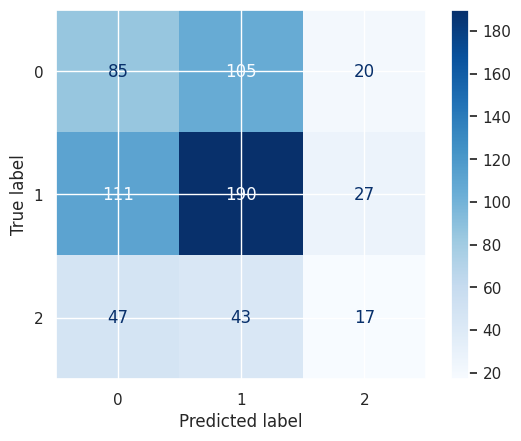

Normalized confusion matrix


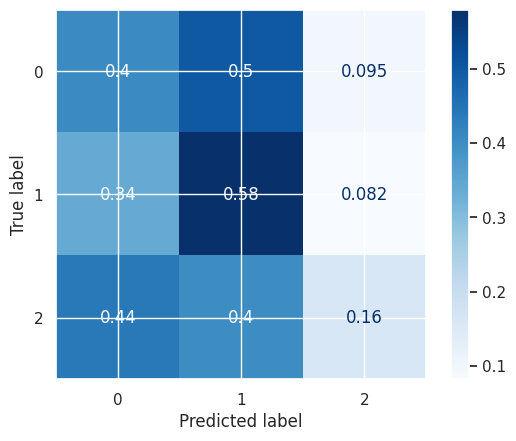

In [53]:
# Confusion matrix without normalization
print('Confusion matrix')
cm = confusion_matrix(y_test, pred)
ConfusionMatrixDisplay(confusion_matrix=cm).plot(cmap='Blues')
plt.show()

# Normalized confusion matrix
print('Normalized confusion matrix')
cm_normalized = confusion_matrix(y_test, pred, normalize='true')
ConfusionMatrixDisplay(confusion_matrix=cm_normalized).plot(cmap='Blues')
plt.show()

In [44]:
# Calculate the four performance metrics and the ROC AUC of the model
evaluate('K-Nearest Neighbors', knn, pred)

Accuracy: 0.4527
Precision: 0.4438
Recall: 0.4527
F1-score: 0.4453
ROC AUC: 0.5702


Result: KNN has an accuracy of **0.4527** (ROC AUC 0.5702), close to the Decision Tree. It predicts Hybrid for 85 of the 210 Hybrid employees but makes many mistakes for the Onsite class (111 Onsite employees are predicted as Hybrid).

## 5.6 Results summary and the best model

In [45]:
# Comparing the four models using the four performance metrics + ROC AUC
results_df = pd.DataFrame(results).T.round(4)
results_df

,Accuracy,Precision,Recall,F1-score,ROC AUC
Logistic Regression,0.5287,0.4983,0.5287,0.4767,0.6528
Decision Tree,0.4496,0.4612,0.4496,0.4547,0.5553
Random Forest,0.5535,0.5199,0.5535,0.5256,0.6701
K-Nearest Neighbors,0.4527,0.4438,0.4527,0.4453,0.5702


#Which model is the best?
- **Best model: Random Forest** (Accuracy 0.5535, Precision 0.5199, Recall 0.5535, F1-score 0.5256, ROC AUC 0.6701). It has the best value in every metric.


# 6. Model Deployment using Streamlit

 we deploy the best-performing model (**Random Forest**) as a web application. The app takes four numerical inputs: Age, Hours_Per_Week, Work_Life_Balance_Score and Social_Isolation_Score.

### Part 1: Select the features and the target, split the data and train the model

In [47]:
import joblib

# Select the features and the target from the cleaned dataset
X_app = df[['Age', 'Hours_Per_Week', 'Work_Life_Balance_Score', 'Social_Isolation_Score']]
y_app = df['Work_Arrangement']

# Split
X_app_train, X_app_test, y_app_train, y_app_test = train_test_split(X_app, y_app, test_size=0.2, random_state=42)

# The best-performing model from section 5.6 (highest accuracy)
best_model_name = 'Random Forest'

# The models we trained (the best one is selected by its name)
candidates = {
    'Logistic Regression': LogisticRegression(),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=0),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=4)
}

# Train the best model (with the scaler in a pipeline so the app needs only one file)
app_model = make_pipeline(StandardScaler(), candidates[best_model_name])
app_model.fit(X_app_train, y_app_train)

# Evaluate
accuracy = app_model.score(X_app_test, y_app_test)
print("Best model:", best_model_name)
print("Accuracy:", accuracy)

Best model: Random Forest
Accuracy: 0.5069767441860465


### Part 2: Save the trained model
We use `joblib` to save the model for later loading in the Streamlit app.

In [48]:
# Save
joblib.dump(app_model, "work_model.pkl")
print("Saved model to work_model.pkl")

Saved model to work_model.pkl


### Part 3: Create the Streamlit app
The cell below writes `app.py` automatically in the same folder.

In [49]:
# Write a complete Streamlit app to app.py
app_code = """import streamlit as st
import pandas as pd
import joblib

# Load the saved model
model = joblib.load("work_model.pkl")

st.title("Work Arrangement Predictor")
st.write("Predicting the work arrangement (Onsite, Hybrid or Remote) of an employee.")

# Inputs
age = st.number_input("Age", 18, 70, 30)
hours_per_week = st.number_input("Hours Per Week", 1, 100, 40)
balance = st.number_input("Work-Life Balance Score (1-5)", 1, 5, 3)
isolation = st.number_input("Social Isolation Score (1-5)", 1, 5, 3)

if st.button("Predict"):
    # Create DataFrame matching the training columns
    input_df = pd.DataFrame([[age, hours_per_week, balance, isolation]],
                            columns=["Age", "Hours_Per_Week", "Work_Life_Balance_Score", "Social_Isolation_Score"])

    # Prediction
    pred = model.predict(input_df)[0]
    st.success("Result: Predicted Work Arrangement is " + str(pred))
"""

with open("app.py", "w", encoding="utf-8") as f:
    f.write(app_code)

print("Wrote app.py to current folder. You can now run 'streamlit run app.py'")

Wrote app.py to current folder. You can now run 'streamlit run app.py'


### Part 4: Run the app


**streamlit run app.py**


The deployed app: https://work-predictor-k23ks3vrcfm8elyascatcq.streamlit.app/

# 7. Conclusion

In this project we studied the post-pandemic remote work dataset (3157 employees, 14 columns) to understand how the work arrangement (Onsite, Hybrid, Remote) is related to health and lifestyle.


- **Preprocessing:** Mental_Health_Status and Physical_Health_Issues had missing values, so we removed those rows (2150 rows left). There were no duplicates and no outliers.
- **EDA:** Remote employees had the highest social isolation score (3.54) and the highest share of High burnout (46.7%), while Onsite employees had the lowest isolation (2.37) and the highest share of Low burnout (30.3%). The numerical variables were almost uncorrelated with each other.
- **Models:** We trained Logistic Regression, Decision Tree, Random Forest and KNN and evaluated them with Accuracy, Precision, Recall, F1-score and ROC AUC. **Random Forest was the best model (accuracy 0.5535, ROC AUC 0.6701)** and the Decision Tree was the worst (accuracy 0.4496).
- **Limitation:** The best accuracy is only slightly higher than always predicting Onsite (0.5085), so the available features give limited information about the work arrangement.
- **Deployment:** The Random Forest model was deployed as a Streamlit web application.